# panel based grid

In [ ]:
case_grid =r'D:\shanghai workshop\vector\visual.shp'

# clip
# 00 lst

In [ ]:
import rasterio
import geopandas as gpd
from rasterio.mask import mask
import os

def split_raster_by_grid(original_raster, grid_path, output_dir):
    # 读取矢量网格
    grid = gpd.read_file(grid_path)

    # 创建输出目录
    os.makedirs(output_dir, exist_ok=True)

    with rasterio.open(original_raster) as src:
        raster_crs = src.crs
        print("📌 原始栅格坐标系:", raster_crs)

        # 坐标系统一
        if grid.crs != raster_crs:
            print("🔄 正在将矢量网格投影为与栅格一致的坐标系...")
            grid = grid.to_crs(raster_crs)

        for _, row in grid.iterrows():
            tile_id = row["ID"]  # 使用 grid 中的 ID 字段
            geom = [row.geometry]

            try:
                out_image, out_transform = mask(src, geom, crop=True)
            except Exception as e:
                print(f"⚠️ 跳过 ID={tile_id}，裁剪失败: {e}")
                continue

            out_meta = src.meta.copy()
            out_meta.update({
                "height": out_image.shape[1],
                "width": out_image.shape[2],
                "transform": out_transform,
                "crs": raster_crs
            })

            out_path = os.path.join(output_dir, f"lst_tile_{tile_id}.tif")
            with rasterio.open(out_path, "w", **out_meta) as dst:
                dst.write(out_image)

            print(f"✅ 已保存切块: {out_path}")

# 示例调用
split_raster_by_grid(

    original_raster=r'D:\shanghai workshop\lst\original\final_lst\clipped_20200816_B10_cleaned_LST.tif',
    grid_path=r'D:\shanghai workshop\vector\visual.shp',
    output_dir=r"D:\shanghai workshop\raster\visual\lst_merge"
)

# 01 water

In [ ]:
import geopandas as gpd
import rasterio
from rasterio.features import rasterize
from rasterio.transform import from_origin
import os

def rasterize_fclass_by_grid(shapefile_path, grid_path, fclass_mapping, output_dir, resolution):
    # 读取水体数据和网格
    gdf = gpd.read_file(shapefile_path)
    grid = gpd.read_file(grid_path)

    # 坐标系统一为 UTM 51N
    if not gdf.crs.is_projected:
        gdf = gdf.to_crs(epsg=32651)
    if not grid.crs.is_projected:
        grid = grid.to_crs(epsg=32651)
    if gdf.crs != grid.crs:
        grid = grid.to_crs(gdf.crs)

    # 保留指定类别的记录，并转换为数值
    gdf = gdf[gdf['fclass'].isin(fclass_mapping.keys())]
    gdf['class_val'] = gdf['fclass'].map(fclass_mapping)

    # 清理空 geometry
    gdf = gdf[~gdf.geometry.is_empty & gdf.geometry.notnull()]
    grid = grid[~grid.geometry.is_empty & grid.geometry.notnull()]

    os.makedirs(output_dir, exist_ok=True)

    for _, cell in grid.iterrows():
        tile_id = cell["ID"]  # 使用 ID 字段作为输出文件名
        grid_geom = cell.geometry

        # 裁剪出当前格子内的水体
        clipped = gpd.overlay(gdf, gpd.GeoDataFrame(geometry=[grid_geom], crs=gdf.crs), how="intersection")

        if clipped.empty:
            continue

        # 计算输出 raster 尺寸
        minx, miny, maxx, maxy = grid_geom.bounds
        width = int((maxx - minx) / resolution)
        height = int((maxy - miny) / resolution)
        transform = from_origin(minx, maxy, resolution, resolution)

        # 构造 shapes
        shapes = [(geom, val) for geom, val in zip(clipped.geometry, clipped['class_val'])]

        raster = rasterize(
            shapes=shapes,
            out_shape=(height, width),
            transform=transform,
            fill=255,  # Nodata 为 255
            dtype='uint8'
        )

        out_path = os.path.join(output_dir, f"water_tile_{tile_id}.tif")

        with rasterio.open(
            out_path,
            "w",
            driver="GTiff",
            height=height,
            width=width,
            count=1,
            dtype="uint8",
            crs=gdf.crs,
            transform=transform,
            nodata=255
        ) as dst:
            dst.write(raster, 1)

        print(f"✅ 输出: {out_path}")

# 示例调用
fclass_mapping = {
    'dock': 0,
    'reservoir': 1,
    'riverbank': 2,
    'water': 3,
    'wetland': 4
}

rasterize_fclass_by_grid(
    shapefile_path=r"D:\BaiduNetdiskDownload\3-shanghai-latest-free.shp\gis_osm_water_a_free_1.shp",
    grid_path=rf"D:\shanghai workshop\vector\visual.shp",
    fclass_mapping=fclass_mapping,
    output_dir=r"D:\shanghai workshop\raster\visual\water_merge",
    resolution=2
)

# 02 building

In [ ]:
import geopandas as gpd
import rasterio
from rasterio.features import rasterize
from rasterio.transform import from_origin
import os
import numpy as np

def rasterize_multiple_fields_to_multiband(shapefile_path, grid_path, class_fields, output_dir, resolution=10, nodata=255):
    gdf = gpd.read_file(shapefile_path)
    grid = gpd.read_file(grid_path)

    if not gdf.crs.is_projected:
        gdf = gdf.to_crs(epsg=32651)
    if not grid.crs.is_projected:
        grid = grid.to_crs(epsg=32651)
    if gdf.crs != grid.crs:
        grid = grid.to_crs(gdf.crs)

    gdf = gdf[~gdf.geometry.is_empty & gdf.geometry.notnull()]
    grid = grid[~grid.geometry.is_empty & grid.geometry.notnull()]

    os.makedirs(output_dir, exist_ok=True)

    # ✅ 第一步：提前为所有字段生成全局映射字典
    field_maps = {}
    for field in class_fields:
        if field not in gdf.columns:
            raise ValueError(f"字段 {field} 不存在于 shapefile 中")
        if gdf[field].dtype.kind in ['O', 'U']:  # 字符型
            unique_vals = sorted(gdf[field].dropna().unique())
            val_map = {v: i+1 for i, v in enumerate(unique_vals)}
            print(f"字段 {field} 的映射：{val_map}")
            field_maps[field] = val_map
            gdf[f"__mapped_{field}"] = gdf[field].map(val_map).fillna(0).astype(int)
        else:
            gdf[f"__mapped_{field}"] = gdf[field].fillna(0)

    for idx, cell in grid.iterrows():
        grid_geom = cell.geometry
        clipped = gpd.overlay(gdf, gpd.GeoDataFrame(geometry=[grid_geom], crs=gdf.crs), how="intersection")
        if clipped.empty:
            continue

        minx, miny, maxx, maxy = grid_geom.bounds
        width = int((maxx - minx) / resolution)
        height = int((maxy - miny) / resolution)
        transform = from_origin(minx, maxy, resolution, resolution)

        bands = []

        for field in class_fields:
            mapped_col = f"__mapped_{field}"
            class_vals = clipped[mapped_col]
            shapes = [(geom, val) for geom, val in zip(clipped.geometry, class_vals)]

            raster = rasterize(
                shapes=shapes,
                out_shape=(height, width),
                transform=transform,
                fill=nodata,
                dtype='uint8' if class_vals.dtype == int else 'float32'
            )
            bands.append(raster)

        bands_array = np.stack(bands, axis=0)
        tile_id = cell["ID"]
        out_path = os.path.join(output_dir, f"building_tile_{tile_id}.tif")

        with rasterio.open(
            out_path,
            "w",
            driver="GTiff",
            height=height,
            width=width,
            count=len(class_fields),
            dtype=bands_array.dtype,
            crs=gdf.crs,
            transform=transform,
            nodata=nodata
        ) as dst:
            dst.write(bands_array)

        print(f"✅ 输出: {out_path}")


# 示例调用
rasterize_multiple_fields_to_multiband(
    shapefile_path=r'D:\shanghai workshop\vector\Building_processed nearest 1 to 500m_finver\result\building_UTM51N.shp',
    grid_path=r"D:\shanghai workshop\vector\visual.shp",
    class_fields=["Height", "Function", "Style"],
    output_dir=r"D:\shanghai workshop\raster\visual\building_merge",
    resolution=1,
    nodata=255
)


# 03 street

In [ ]:
import geopandas as gpd
import rasterio
from rasterio.features import rasterize
from rasterio.transform import from_origin
import os

def rasterize_by_grid_with_auto_class_mapping(shapefile_path, grid_path, class_field, output_dir, resolution=10, nodata=255):
    # 读取数据
    gdf = gpd.read_file(shapefile_path)
    grid = gpd.read_file(grid_path)

    # 坐标系统统一为投影坐标系（UTM 51N）
    if not gdf.crs.is_projected:
        gdf = gdf.to_crs(epsg=32651)
    if not grid.crs.is_projected:
        grid = grid.to_crs(epsg=32651)
    if gdf.crs != grid.crs:
        grid = grid.to_crs(gdf.crs)

    # 清理无效几何
    gdf = gdf[~gdf.geometry.is_empty & gdf.geometry.notnull()]
    grid = grid[~grid.geometry.is_empty & grid.geometry.notnull()]

    # 检查字段是否存在
    if class_field not in gdf.columns:
        raise ValueError(f"字段 {class_field} 不存在于 shapefile 中")

    # 获取字段的唯一值列表，并生成映射字典（类别字符串->数字ID，从1开始，0 留作背景）
    unique_classes = sorted(gdf[class_field].dropna().unique())
    class_to_id = {cls: idx+1 for idx, cls in enumerate(unique_classes)}
    print(f"自动生成类别映射（{class_field}）：{class_to_id}")

    # 用映射替换原字段，未包含的赋值0
    gdf['class_val'] = gdf[class_field].map(class_to_id).fillna(0).astype(int)

    os.makedirs(output_dir, exist_ok=True)

    for idx, cell in grid.iterrows():
        grid_geom = cell.geometry

        clipped = gpd.overlay(gdf, gpd.GeoDataFrame(geometry=[grid_geom], crs=gdf.crs), how="intersection")
        if clipped.empty:
            continue

        minx, miny, maxx, maxy = grid_geom.bounds
        width = int((maxx - minx) / resolution)
        height = int((maxy - miny) / resolution)
        transform = from_origin(minx, maxy, resolution, resolution)

        shapes = [(geom, val) for geom, val in zip(clipped.geometry, clipped['class_val'])]

        raster = rasterize(
            shapes=shapes,
            out_shape=(height, width),
            transform=transform,
            fill=nodata,
            dtype='uint8'
        )
        tile_id = cell["ID"]
        out_path = os.path.join(output_dir, f"tile_{tile_id}.tif")

        with rasterio.open(
            out_path,
            "w",
            driver="GTiff",
            height=height,
            width=width,
            count=1,
            dtype="uint8",
            crs=gdf.crs,
            transform=transform,
            nodata=nodata
        ) as dst:
            dst.write(raster, 1)

        print(f"✅ 输出: {out_path}")

# 使用示例
rasterize_by_grid_with_auto_class_mapping(
    shapefile_path=r"D:\shanghai workshop\vector\Shanghai street_ver3\Shanghai street_ver3.shp",
    grid_path=r"D:\shanghai workshop\vector\visual.shp",
    class_field="Type",
    output_dir=r"D:\shanghai workshop\raster\visual\street_merge",
    resolution=1,
    nodata=255
)

# 04 park

In [ ]:
import geopandas as gpd
import rasterio
from rasterio.features import rasterize
from rasterio.transform import from_origin
import os

def rasterize_park_by_grid(parks_shp, grid_shp, output_folder, resolution=10):
    # 读取数据
    parks = gpd.read_file(parks_shp)
    grid = gpd.read_file(grid_shp)

    # 坐标系统一（建议米制）
    if not parks.crs.is_projected:
        parks = parks.to_crs(epsg=32651)
    if not grid.crs.is_projected:
        grid = grid.to_crs(parks.crs)
    elif parks.crs != grid.crs:
        grid = grid.to_crs(parks.crs)

    # 清理空 geometry
    parks = parks[~parks.geometry.is_empty & parks.geometry.notnull()]
    grid = grid[~grid.geometry.is_empty & grid.geometry.notnull()]

    os.makedirs(output_folder, exist_ok=True)

    for _, row in grid.iterrows():
        tile_id = row["ID"]  # 使用网格的 ID 字段作为文件名
        grid_geom = row.geometry

        # 提取该格网内的公园
        clipped = gpd.overlay(parks, gpd.GeoDataFrame(geometry=[grid_geom], crs=parks.crs), how="intersection")

        if clipped.empty:
            continue  # 如果该区域没有公园，跳过

        # 计算 raster 尺寸
        minx, miny, maxx, maxy = grid_geom.bounds
        width = int((maxx - minx) / resolution)
        height = int((maxy - miny) / resolution)
        transform = from_origin(minx, maxy, resolution, resolution)

        # 准备 raster 数据
        shapes = [(geom, 1) for geom in clipped.geometry]
        raster = rasterize(
            shapes,
            out_shape=(height, width),
            transform=transform,
            fill=0,
            dtype="uint8"
        )

        # 输出路径
        out_path = os.path.join(output_folder, f"park_tile_{tile_id}.tif")

        # 写入 raster
        with rasterio.open(
            out_path,
            "w",
            driver="GTiff",
            height=height,
            width=width,
            count=1,
            dtype="uint8",
            crs=parks.crs,
            transform=transform
        ) as dst:
            dst.write(raster, 1)

        print(f"✅ Saved: {out_path}")

# 示例调用
rasterize_park_by_grid(
    parks_shp=r"D:\shanghai workshop\building+park+waterbody\landuse-公园用地\landuse_park.shp",
    grid_shp= r"D:\shanghai workshop\vector\visual.shp",
    output_folder=r"D:\shanghai workshop\raster\visual\park_merge",
    resolution=2  # 2米分辨率
)

# 05 landuse

In [ ]:
import geopandas as gpd
import rasterio
from rasterio.features import rasterize
from rasterio.transform import from_origin
import os

def rasterize_level2_by_grid(shapefile_path, grid_path, output_dir, resolution):
    # 读取数据
    gdf = gpd.read_file(shapefile_path)
    grid = gpd.read_file(grid_path)

    # 坐标系统一为 UTM 51N
    gdf = gdf.to_crs(epsg=32651)
    grid = grid.to_crs(epsg=32651)

    # 清理无效 geometry
    gdf = gdf[~gdf.geometry.is_empty & gdf.geometry.notnull()]
    grid = grid[~grid.geometry.is_empty & grid.geometry.notnull()]

    # 映射 level2_cn 为整数编码
    categories = sorted(gdf["Level2_cn"].dropna().unique())
    label_mapping = {cat: idx for idx, cat in enumerate(categories)}
    gdf["class_val"] = gdf["Level2_cn"].map(label_mapping)

    print("📋 自动编码映射如下：")
    for k, v in label_mapping.items():
        print(f"  {v}: {k}")

    os.makedirs(output_dir, exist_ok=True)

    for _, cell in grid.iterrows():
        tile_id = cell["ID"]
        grid_geom = cell.geometry

        clipped = gpd.overlay(gdf, gpd.GeoDataFrame(geometry=[grid_geom], crs=gdf.crs), how="intersection")

        if clipped.empty:
            continue

        minx, miny, maxx, maxy = grid_geom.bounds
        width = int((maxx - minx) / resolution)
        height = int((maxy - miny) / resolution)
        transform = from_origin(minx, maxy, resolution, resolution)

        shapes = [(geom, val) for geom, val in zip(clipped.geometry, clipped['class_val'])]

        raster = rasterize(
            shapes=shapes,
            out_shape=(height, width),
            transform=transform,
            fill=255,  # 无数据为 255
            dtype='uint8'
        )

        out_path = os.path.join(output_dir, f"landuse_tile_{tile_id}.tif")

        with rasterio.open(
            out_path,
            "w",
            driver="GTiff",
            height=height,
            width=width,
            count=1,
            dtype="uint8",
            crs=gdf.crs,
            transform=transform,
            nodata=255
        ) as dst:
            dst.write(raster, 1)

        print(f"✅ 输出: {out_path}")

# 示例调用
rasterize_level2_by_grid(
    shapefile_path=r'D:\shanghai workshop\building+park+waterbody\按省份划分\上海市.shp',
    grid_path=r"D:\shanghai workshop\vector\visual.shp",
    output_dir=r"D:\shanghai workshop\raster\visual\landuse_tiles",
    resolution=1
)

# 06 merge

In [ ]:
import rasterio
from rasterio.warp import reproject, Resampling as WarpResampling
import numpy as np
import os

def reproject_and_resample_band(src_path, band_idx, ref_crs, ref_transform, ref_width, ref_height):
    try:
        with rasterio.open(src_path) as src:
            dst_array = np.empty((ref_height, ref_width), dtype=np.float32)

            reproject(
                source=rasterio.band(src, band_idx),
                destination=dst_array,
                src_transform=src.transform,
                src_crs=src.crs,
                dst_transform=ref_transform,
                dst_crs=ref_crs,
                resampling=WarpResampling.nearest
            )
            return dst_array
    except Exception as e:
        print(f"❌ 无法读取或重采样 {src_path} 第 {band_idx} 波段：{e}")
        return None

def resample_and_merge_multiband(base_raster, layers_dict, output_path):
    # 🚨 以建筑图层为基准坐标、变换、尺寸
    with rasterio.open(base_raster) as ref:
        dst_crs = ref.crs
        dst_transform = ref.transform
        dst_width = ref.width
        dst_height = ref.height
        ref_meta = ref.meta.copy()

    dtype = np.float32
    nodata_val = np.nan
    layer_order = [
        "water",
        "park",
        "street",
        "building_height",  # band 1
        "building_type",    # band 2
        "building_style",   # band 3
        "landuse",
        "lst"
    ]
    band_count = len(layer_order)

    merged_array = np.full((band_count, dst_height, dst_width), nodata_val, dtype=dtype)

    for i, layer in enumerate(layer_order):
        path = layers_dict.get(layer)

        # 特别处理 building 三个波段
        if layer.startswith("building_"):
            band_map = {
                "building_height": 1,
                "building_type": 2,
                "building_style": 3
            }
            band_index = band_map.get(layer, 1)
        else:
            band_index = 1

        if path and os.path.exists(path):
            print(f"📥 正在处理图层 {layer}: {path} (band {band_index})")
            arr = reproject_and_resample_band(
                path, band_index,
                dst_crs, dst_transform,
                dst_width, dst_height
            )
            if arr is not None:
                valid_mask = (~np.isnan(arr)) & (arr != 0) & (arr != 255)
                cleaned = np.full_like(arr, nodata_val)
                cleaned[valid_mask] = arr[valid_mask]
                merged_array[i] = cleaned
            else:
                print(f"⚠️ 图层 {layer} 重采样失败，保留为 NaN")
        else:
            print(f"⚠️ 图层 {layer} 缺失或路径无效：{path}")

    out_meta = ref_meta.copy()
    out_meta.update({
        "count": band_count,
        "dtype": "float32",
        "height": dst_height,
        "width": dst_width,
        "transform": dst_transform,
        "crs": dst_crs,
        "nodata": nodata_val
    })

    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    with rasterio.open(output_path, "w", **out_meta) as dst:
        dst.write(merged_array)
        print(f"✅ 多波段 GeoTIFF 已保存: {output_path}")
n = 51738
base_raster = rf"D:\shanghai workshop\raster\visual\building_merge\building_tile_{n}.tif"
layers = {
    "building_height": base_raster,
    "building_type": base_raster,
    "building_style": base_raster,
    "park": rf"D:\shanghai workshop\raster\visual\park_merge\park_tile_{n}.tif",
    "water": rf"D:\shanghai workshop\raster\visual\water_merge\water_tile_{n}.tif",
    "street": rf"D:\shanghai workshop\raster\visual\street_merge\tile_{n}.tif",
    "landuse": rf"D:\shanghai workshop\raster\visual\landuse_tiles\landuse_tile_{n}.tif",
    "lst": rf"D:\shanghai workshop\raster\visual\lst_merge\lst_tile_{n}.tif"
}
output_path = rf"D:\shanghai workshop\raster\visual\merge\merged_tile_{n}.tif"
resample_and_merge_multiband(base_raster, layers, output_path)


# 批量裁剪

In [ ]:
import geopandas as gpd

# 替换为你的文件路径
path = r"D:\shanghai workshop\vector\visual.shp"
gdf = gpd.read_file(path)

# 查看字段名确认列是否叫 'ID'
print(gdf.columns)

# 如果列名就是 'ID'，提取它
id_list = gdf['ID'].tolist()
print(id_list)

for n in id_list:
    base_raster = rf"D:\shanghai workshop\raster\visual\building_merge\building_tile_{n}.tif"
    layers = {
    "building_height": rf"D:\shanghai workshop\raster\visual\building_merge\building_tile_{n}.tif",
    "building_type": rf"D:\shanghai workshop\raster\visual\building_merge\building_tile_{n}.tif",
    "building_style": rf"D:\shanghai workshop\raster\visual\building_merge\building_tile_{n}.tif",
    "park": rf"D:\shanghai workshop\raster\visual\park_merge\park_tile_{n}.tif",
    "water": rf"D:\shanghai workshop\raster\visual\water_merge\water_tile_{n}.tif",
    "street": rf"D:\shanghai workshop\raster\visual\street_merge\tile_{n}.tif",
    "landuse": rf"D:\shanghai workshop\raster\visual\landuse_tiles\landuse_tile_{n}.tif",
    "lst": rf"D:\shanghai workshop\raster\visual\lst_merge\lst_tile_{n}.tif"
    }
    output_path = rf"D:\shanghai workshop\raster\visual\merge\merged_tile_{n}.tif"

    # 检查基础图层是否存在（避免文件缺失报错）
    if os.path.exists(base_raster):
        try:
            resample_and_merge_multiband(base_raster, layers, output_path)
        except Exception as e:
            print(f"❌ 处理 tile_{n} 时出错: {e}")
    else:
        print(f"⚠️ 缺失 base_raster: tile_{n}")

# clipped

In [ ]:
import os
import geopandas as gpd
import rasterio
from rasterio.mask import mask

# 读取矢量网格
vector_path = r"D:\shanghai workshop\vector\shanghai_grid_256m_clipped.shp"
gdf = gpd.read_file(vector_path)

# 确保 CRS 和栅格一致（即 EPSG:32651）
gdf = gdf.to_crs(epsg=32651)

# 获取所有 ID 列表
id_list = gdf['ID'].tolist()

# 遍历每个 ID，裁剪同名栅格
for n in id_list:
    input_raster = rf"D:\shanghai workshop\raster\visual\merge\merged_tile_{n}.tif"
    output_raster = rf"D:\shanghai workshop\raster\visual\merge_final\merged_clean_tile_{n}.tif"

    if not os.path.exists(input_raster):
        print(f"⚠️ 跳过缺失文件: merged_tile_{n}.tif")
        continue

    try:
        # 提取该 ID 对应的 polygon
        polygon = gdf[gdf['ID'] == n].geometry.values[0]
        geojson_geom = [polygon.__geo_interface__]

        # 打开栅格并裁剪
        with rasterio.open(input_raster) as src:
            out_image, out_transform = mask(src, geojson_geom, crop=True, nodata=np.nan)
            out_meta = src.meta.copy()

        # 更新元信息
        out_meta.update({
            "height": out_image.shape[1],
            "width": out_image.shape[2],
            "transform": out_transform,
            "nodata": np.nan
        })

        # 写出裁剪后的文件
        os.makedirs(os.path.dirname(output_raster), exist_ok=True)
        with rasterio.open(output_raster, "w", **out_meta) as dest:
            dest.write(out_image)
            print(f"✅ 裁剪完成: clipped_tile_{n}.tif")

    except Exception as e:
        print(f"❌ 裁剪 tile_{n} 出错: {e}")

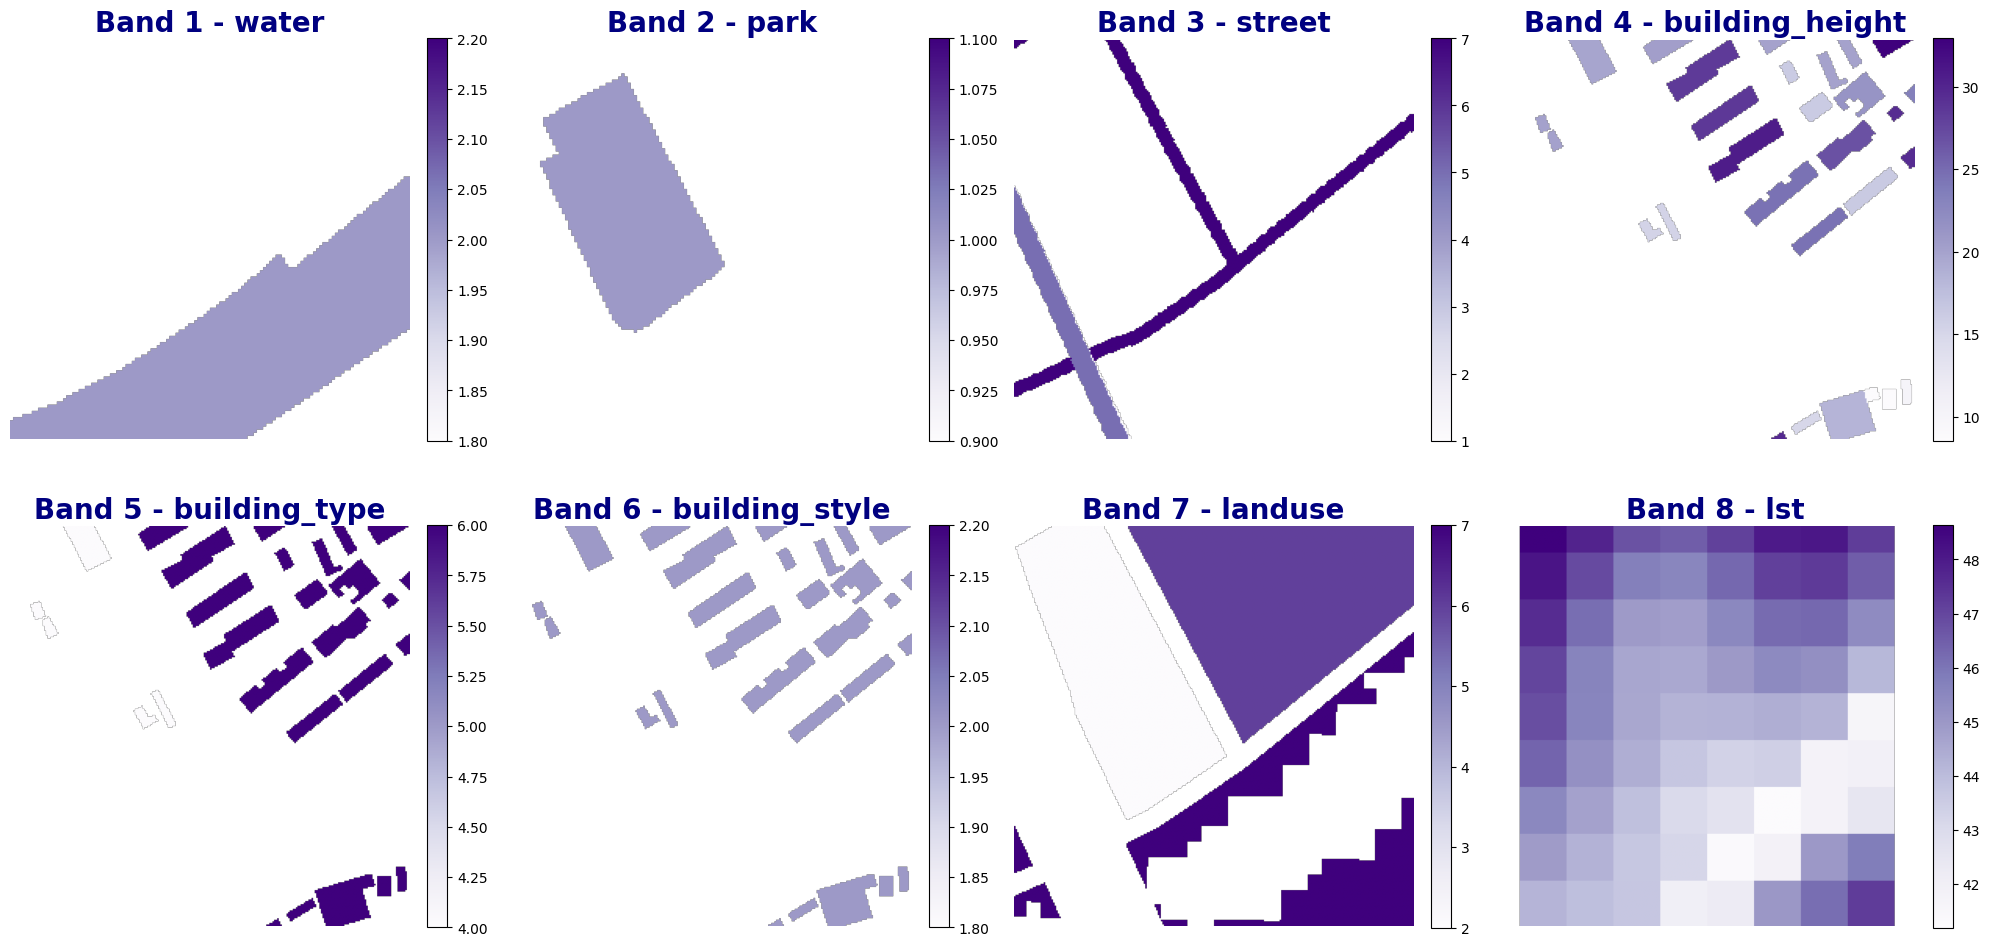

In [89]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

file_path = r"D:\shanghai workshop\raster\merged_multiband\final\multi_merged_tile_192.tif"

band_names = [
    "water",
    "park",
    "street",
    "building_height",
    "building_type",
    "building_style",
    "landuse",
    "lst"
]

with rasterio.open(file_path) as src:
    nodata = -9999
    band_count = src.count

    fig, axes = plt.subplots(2, 4, figsize=(20, 10))
    axes = axes.flatten()

    for i in range(1, band_count + 1):
        band = src.read(i)
        masked_band = np.ma.masked_equal(band, nodata)

        ax = axes[i-1]
        im = ax.imshow(masked_band, cmap="Purples")
        # magma

        # twilight_shifted
        # Purples
        ax.set_title(f"Band {i} - {band_names[i-1]}", fontsize=20, fontweight='bold', color='navy')

        ax.axis('off')
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    plt.tight_layout()
    plt.show()


In [90]:
import os
import shutil
import geopandas as gpd

# 路径设置
merge_folder = r"D:\shanghai workshop\raster\visual\merge_final"
case_shapefile = r"D:\shanghai workshop\vector\case.shp"
output_folder = os.path.join(merge_folder, "merge_final_case")

# 创建输出文件夹
os.makedirs(output_folder, exist_ok=True)

# 读取 shapefile 的 ID 字段
gdf = gpd.read_file(case_shapefile)
case_ids = set(map(str, gdf['ID'].tolist()))  # 转成字符串集合，便于匹配

# 遍历 merge_final 文件夹
for filename in os.listdir(merge_folder):
    if filename.startswith("merged_clean_tile_") and filename.endswith(".tif"):
        # 提取 ID
        tile_id = filename.replace("merged_clean_tile_", "").replace(".tif", "")
        if tile_id in case_ids:
            src_path = os.path.join(merge_folder, filename)
            dst_path = os.path.join(output_folder, filename)
            shutil.copy2(src_path, dst_path)
            print(f"✅ 已复制: {filename}")


✅ 已复制: merged_clean_tile_54143.tif
✅ 已复制: merged_clean_tile_54144.tif
✅ 已复制: merged_clean_tile_54145.tif
✅ 已复制: merged_clean_tile_54146.tif
✅ 已复制: merged_clean_tile_54147.tif
✅ 已复制: merged_clean_tile_54486.tif
✅ 已复制: merged_clean_tile_54487.tif
✅ 已复制: merged_clean_tile_54488.tif
✅ 已复制: merged_clean_tile_54489.tif
✅ 已复制: merged_clean_tile_54490.tif
✅ 已复制: merged_clean_tile_54829.tif
✅ 已复制: merged_clean_tile_54830.tif
✅ 已复制: merged_clean_tile_54831.tif
✅ 已复制: merged_clean_tile_54832.tif
✅ 已复制: merged_clean_tile_54833.tif
✅ 已复制: merged_clean_tile_55172.tif
✅ 已复制: merged_clean_tile_55173.tif
✅ 已复制: merged_clean_tile_55174.tif
✅ 已复制: merged_clean_tile_55175.tif
✅ 已复制: merged_clean_tile_55176.tif
✅ 已复制: merged_clean_tile_55515.tif
✅ 已复制: merged_clean_tile_55516.tif
✅ 已复制: merged_clean_tile_55517.tif
✅ 已复制: merged_clean_tile_55518.tif
✅ 已复制: merged_clean_tile_55519.tif


In [91]:
import os
import rasterio
from rasterio.features import shapes
import numpy as np
import geopandas as gpd
from shapely.geometry import shape

def raster_to_geojson_per_band(input_folder, output_folder, target_epsg=4326):
    os.makedirs(output_folder, exist_ok=True)

    band_names = [
        "water",           # Band 1
        "park",            # Band 2
        "street",          # Band 3
        "building_height", # Band 4
        "building_type",   # Band 5
        "building_style",  # Band 6
        "landuse",         # Band 7
        "lst"              # Band 8
    ]

    for filename in os.listdir(input_folder):
        if filename.lower().endswith(".tif"):
            tif_path = os.path.join(input_folder, filename)

            print(f"📍 正在处理: {tif_path}")

            with rasterio.open(tif_path) as src:
                for i, band_name in enumerate(band_names, start=1):
                    image = src.read(i)
                    mask = (image != src.nodata) & (~np.isnan(image))

                    results = (
                        {"properties": {"value": v}, "geometry": s}
                        for s, v in shapes(image, mask=mask, transform=src.transform)
                    )

                    geoms = list(results)
                    if not geoms:
                        print(f"⚠️ {band_name} 无有效数据，跳过: {filename}")
                        continue

                    gdf = gpd.GeoDataFrame.from_features(geoms, crs=src.crs)
                    gdf = gdf.to_crs(epsg=target_epsg)

                    base_name = filename.replace(".tif", f"_{band_name}.geojson")
                    geojson_path = os.path.join(output_folder, base_name)
                    gdf.to_file(geojson_path, driver="GeoJSON")
                    print(f"✅ {band_name} 已保存为 GeoJSON: {geojson_path}")

# 使用示例
raster_to_geojson_per_band(
    input_folder=r"D:\shanghai workshop\raster\visual\merge_final\merge_final_case",
    output_folder=r"D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output",
    target_epsg=4326
)

📍 正在处理: D:\shanghai workshop\raster\visual\merge_final\merge_final_case\merged_clean_tile_54143.tif
⚠️ water 无有效数据，跳过: merged_clean_tile_54143.tif
⚠️ park 无有效数据，跳过: merged_clean_tile_54143.tif
✅ street 已保存为 GeoJSON: D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output\merged_clean_tile_54143_street.geojson
✅ building_height 已保存为 GeoJSON: D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output\merged_clean_tile_54143_building_height.geojson
✅ building_type 已保存为 GeoJSON: D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output\merged_clean_tile_54143_building_type.geojson
✅ building_style 已保存为 GeoJSON: D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output\merged_clean_tile_54143_building_style.geojson
✅ landuse 已保存为 GeoJSON: D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output\merged_clean_tile_54143_landuse.geojson
✅ lst 已保存为 GeoJSON: D:\shanghai workshop\raster\visu

In [92]:
import os
import geopandas as gpd
from collections import defaultdict

input_folder = r'D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output'
output_folder = os.path.join(input_folder, 'merged_by_type')
os.makedirs(output_folder, exist_ok=True)

# 按照类型（如 building_height）分组
layer_groups = defaultdict(list)

for filename in os.listdir(input_folder):
    if filename.endswith('.geojson'):
        # 提取类型部分，如：merged_clean_tile_51738_building_height.geojson
        parts = filename.replace('.geojson', '').split('_')
        if len(parts) >= 2:
            layer_type = parts[-1]  # 取最后一段作为类型
            layer_groups[layer_type].append(os.path.join(input_folder, filename))

# 遍历每组进行合并
for layer_type, file_list in layer_groups.items():
    merged_gdf = gpd.GeoDataFrame()

    for file_path in file_list:
        print(f"📥 读取: {file_path}")
        gdf = gpd.read_file(file_path)
        merged_gdf = gpd.pd.concat([merged_gdf, gdf], ignore_index=True)

    output_path = os.path.join(output_folder, f'merged_{layer_type}.geojson')
    merged_gdf.to_file(output_path, driver='GeoJSON')
    print(f"✅ 已保存合并文件: {output_path}")


📥 读取: D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output\merged_clean_tile_54143_building_height.geojson
📥 读取: D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output\merged_clean_tile_54144_building_height.geojson
📥 读取: D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output\merged_clean_tile_54145_building_height.geojson
📥 读取: D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output\merged_clean_tile_54146_building_height.geojson
📥 读取: D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output\merged_clean_tile_54147_building_height.geojson
📥 读取: D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output\merged_clean_tile_54486_building_height.geojson
📥 读取: D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output\merged_clean_tile_54487_building_height.geojson
📥 读取: D:\shanghai workshop\raster\visual\merge_final\merge_final_case

In [96]:
!{sys.executable} -m pip install scikit-image

Defaulting to user installation because normal site-packages is not writeable
  Using cached lazy_loader-0.4-py3-none-any.whl.metadata (7.6 kB)
   ---------------------------------------- 0.0/12.9 MB ? eta -:--:--
   ----- ---------------------------------- 1.8/12.9 MB 9.1 MB/s eta 0:00:02
   ------------ --------------------------- 3.9/12.9 MB 9.8 MB/s eta 0:00:01
   ----------------- ---------------------- 5.8/12.9 MB 9.5 MB/s eta 0:00:01
   ------------------------ --------------- 7.9/12.9 MB 9.7 MB/s eta 0:00:01
   -------------------------- ------------- 8.4/12.9 MB 8.8 MB/s eta 0:00:01
   ---------------------------- ----------- 9.2/12.9 MB 7.4 MB/s eta 0:00:01
   -------------------------------- ------- 10.5/12.9 MB 7.2 MB/s eta 0:00:01
   -------------------------------------- - 12.3/12.9 MB 7.3 MB/s eta 0:00:01
   ---------------------------------------- 12.9/12.9 MB 7.3 MB/s eta 0:00:00
Using cached lazy_loader-0.4-py3-none-any.whl (12 kB)

   --------------------------------

In [1]:
# import rasterio
# from rasterio.merge import merge
# import os
#
# # 输入文件路径
# tif1 = r"D:\shanghai workshop\raster\visual\merge_final\merge_final_case\merged_clean_tile_54143.tif"
# tif2 = r"D:\shanghai workshop\raster\visual\merge_final\merge_final_case\merged_clean_tile_54144.tif"
#
# # 打开两个栅格
# src1 = rasterio.open(tif1)
# src2 = rasterio.open(tif2)
#
# # 拼接
# mosaic, out_transform = merge([src1, src2], nodata=np.nan)
#
# # 元数据更新
# out_meta = src1.meta.copy()
# out_meta.update({
#     "height": mosaic.shape[1],
#     "width": mosaic.shape[2],
#     "transform": out_transform,
#     "nodata": np.nan
# })
#
# # 输出路径
# output_path = r"D:\shanghai workshop\raster\visual\merge_final\merge_final_case\merged_all_layers_1.tif"
#
# os.makedirs(os.path.dirname(output_path), exist_ok=True)
#
# # 写出结果
# with rasterio.open(output_path, "w", **out_meta) as dest:
#     dest.write(mosaic)
#
# # 关闭文件
# src1.close()
# src2.close()
#
# print(f"✅ 已成功拼接: {output_path}")
import os
import rasterio
from rasterio.merge import merge
import numpy as np

def mosaic_folder(input_folder, output_path):
    # 获取所有 tif 文件
    tif_files = [
        os.path.join(input_folder, f)
        for f in os.listdir(input_folder)
        if f.lower().endswith(".tif")
    ]

    if not tif_files:
        print("⚠️ 没有找到任何 .tif 文件。")
        return

    # 打开所有 tif 文件
    src_list = [rasterio.open(fp) for fp in tif_files]

    # 执行拼接
    mosaic, out_transform = merge(src_list, nodata=np.nan)

    # 使用第一个图像的元数据作为模板
    out_meta = src_list[0].meta.copy()
    out_meta.update({
        "height": mosaic.shape[1],
        "width": mosaic.shape[2],
        "transform": out_transform,
        "nodata": np.nan,
        "count": mosaic.shape[0]  # 波段数
    })

    # 创建输出文件夹（如果需要）
    os.makedirs(os.path.dirname(output_path), exist_ok=True)

    # 写出合并结果
    with rasterio.open(output_path, "w", **out_meta) as dest:
        dest.write(mosaic)

    # 清理资源
    for src in src_list:
        src.close()

    print(f"✅ 已成功拼接并保存为: {output_path}")

# 示例调用
input_dir = r"D:\shanghai workshop\raster\visual\merge_final\merge_final_case"
output_tif = os.path.join(input_dir, "merged_all_layers.tif")
mosaic_folder(input_dir, output_tif)


✅ 已成功拼接并保存为: D:\shanghai workshop\raster\visual\merge_final\merge_final_case\merged_all_layers.tif


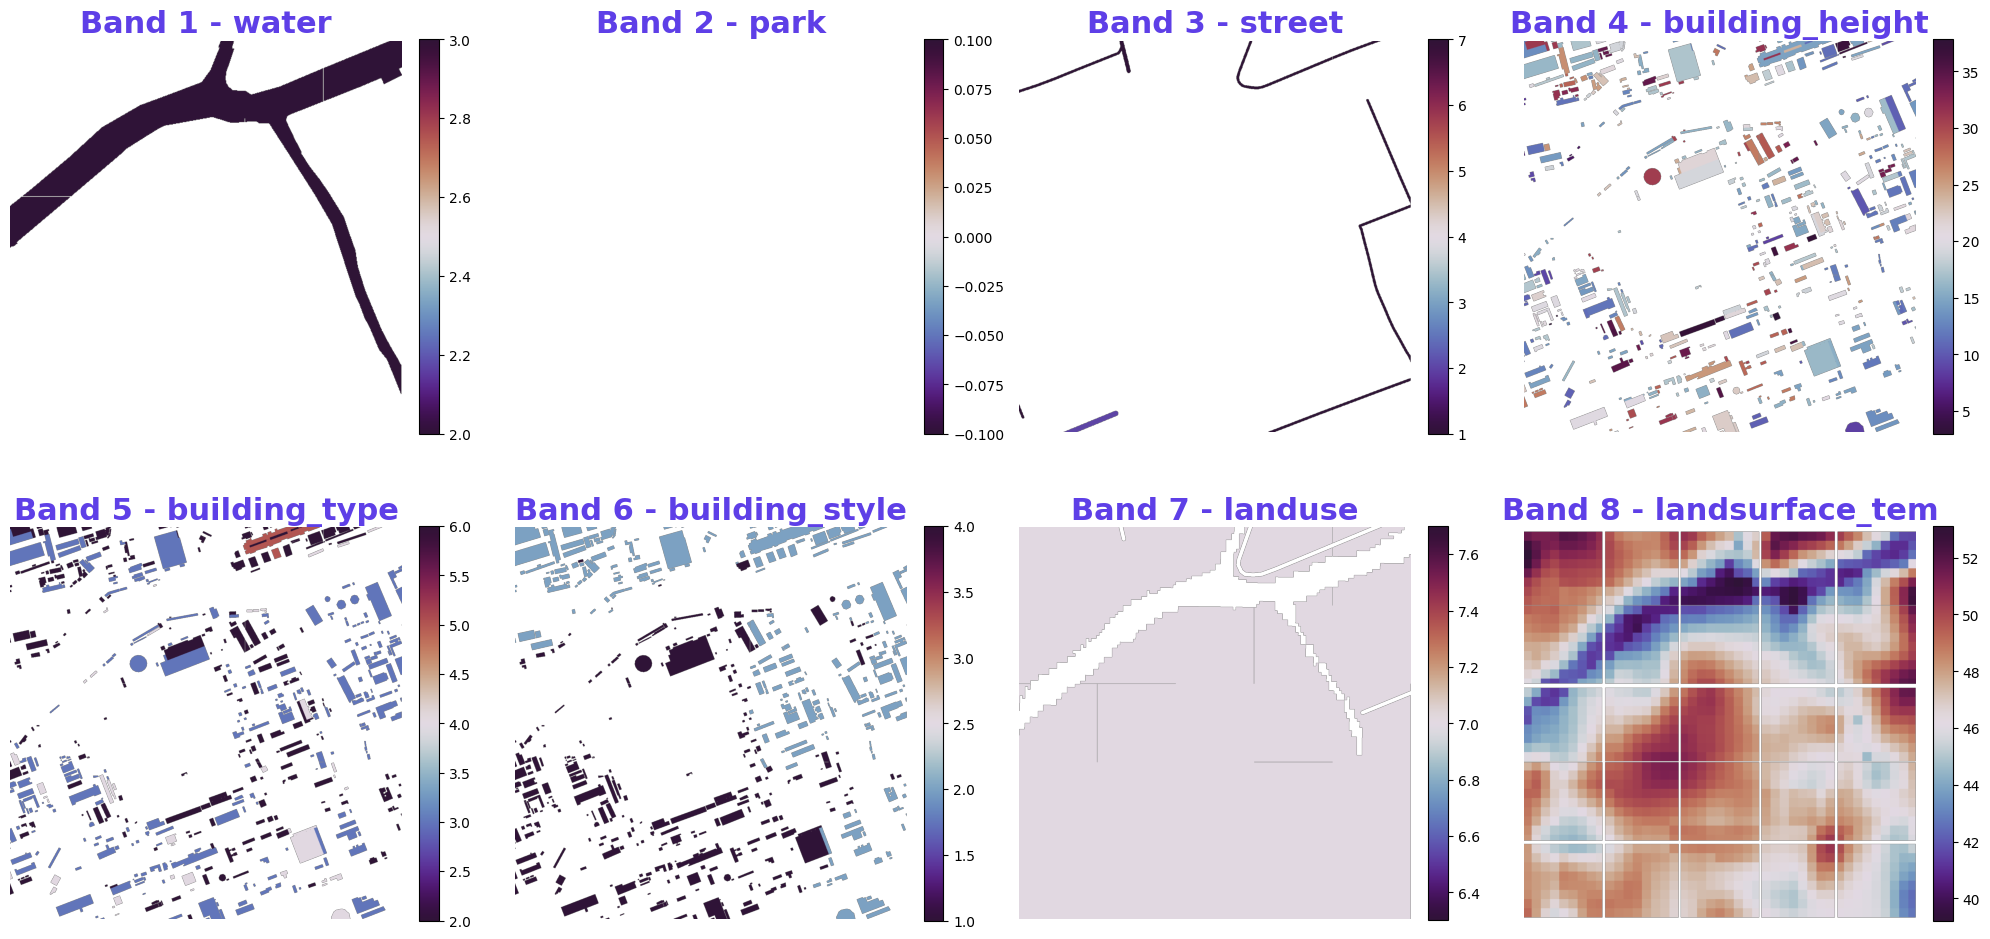

In [6]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

file_path = r"D:\shanghai workshop\raster\visual\merge_final\merge_final_case\merged_all_layers.tif"#D:\shanghai workshop\raster\merged_multiband\merged_tile_192.tif

band_names = [
    "water",
    "park",
    "street",
    "building_height",
    "building_type",
    "building_style",
    "landuse",
    "landsurface_tem"
]

with rasterio.open(file_path) as src:
    nodata = -9999
    band_count = src.count

    fig, axes = plt.subplots(2, 4, figsize=(20, 10))
    axes = axes.flatten()

    for i in range(1, band_count + 1):
        band = src.read(i)
        masked_band = np.ma.masked_equal(band, nodata)

        ax = axes[i-1]
        im = ax.imshow(masked_band, cmap="twilight_shifted")
        # magma

        # twilight_shifted
        # Purples
        ax.set_title(f"Band {i} - {band_names[i-1]}", fontsize=22, fontweight='bold', color='#5E3FE7')

        ax.axis('off')
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    plt.tight_layout()
    plt.show()


In [ ]:
r"D:\shanghai workshop\raster\visual\merge_final\merge_final_case\merged_all_layers.tif"

In [14]:
import os
import glob
import rasterio
import numpy as np
import json
from shapely.geometry import mapping, Point, Polygon
from shapely.ops import unary_union
from skimage.filters import gaussian
from skimage.measure import find_contours, approximate_polygon
import pyproj

# 属性映射表
fclass_mapping = {0: 'dock', 1: 'reservoir', 2: 'riverbank', 3: 'water', 4: 'wetland'}
street_mapping = {1: '中心城区主要道路', 2: '中心城区道路', 3: '主干道路', 4: '公路', 5: '快速路', 6: '快速路匝道', 7: '支路', 8: '郊县中心城区主干道路', 9: '高速', 10: '高速公路匝道'}
building_type_mapping = {1: 'Business', 2: 'Industry', 3: 'Office', 4: 'Other', 5: 'Public service', 6: 'Residence'}
building_style_mapping = {1: 'M', 2: 'Modern', 3: 'Postmodern', 4: 'Traditional'}
landuse_mapping = {
    0: '交通场站用地', 1: '体育与文化用地', 2: '公园与绿地用地', 3: '医疗卫生用地', 4: '商业服务用地',
    5: '商务办公用地', 6: '居住用地', 7: '工业用地', 8: '教育科研用地', 9: '机场设施用地', 10: '行政办公用地'
}

input_folder = r"D:\shanghai workshop\raster\visual\merge_final\merge_final_case\merged_all_layers"
output_folder = r"D:\shanghai workshop\raster\visual\merge_final\merge_final_case\merged_all_layers\merge_jeoJSON"
os.makedirs(output_folder, exist_ok=True)

proj_utm51 = pyproj.CRS.from_epsg(32651)
proj_wgs84 = pyproj.CRS.from_epsg(4326)
transformer = pyproj.Transformer.from_crs(proj_utm51, proj_wgs84, always_xy=True)

def band_to_polygons(band, transform, sigma=1.2, tolerance=2.0, mask_value=1):
    # mask_value: 需要提取的像元值（如1或其它）
    mask = (band == mask_value)
    if not np.any(mask):
        return []
    mask_smooth = gaussian(mask.astype(float), sigma=sigma) > 0.5
    contours = find_contours(mask_smooth, 0.5)
    polygons = []
    for contour in contours:
        coords = [rasterio.transform.xy(transform, y, x) for y, x in contour]
        coords = approximate_polygon(np.array(coords), tolerance)
        if len(coords) > 3:
            # 坐标投影转换
            coords_wgs84 = [transformer.transform(x, y) for x, y in coords]
            polygons.append(Polygon(coords_wgs84))
    return polygons

def save_geojson(features, out_path):
    geojson_dict = {
        "type": "FeatureCollection",
        "features": features
    }
    with open(out_path, "w", encoding="utf-8") as f:
        json.dump(geojson_dict, f, ensure_ascii=False, indent=2)

for tif_path in glob.glob(os.path.join(input_folder, "*.tif")):
    features = []
    with rasterio.open(tif_path) as src:
        bands = [src.read(i+1) for i in range(8)]
        transform = src.transform
        nodata = src.nodata
        rows, cols = bands[0].shape

        # 1. LST点
        for row in range(rows):
            for col in range(cols):
                lst = bands[7][row, col]
                if nodata is not None and lst == nodata:
                    continue
                x, y = rasterio.transform.xy(transform, row, col, offset='center')
                lon, lat = transformer.transform(x, y)
                point = Point(lon, lat)
                feature = {
                    "type": "Feature",
                    "geometry": mapping(point),
                    "properties": {"kind": "lst", "lst": float(lst)}
                }
                features.append(feature)

        # 2. 其它波段多边形（如water、park、street、building等）
        # water
        for v in np.unique(bands[0]):
            if v == nodata: continue
            polygons = band_to_polygons(bands[0], transform, mask_value=v)
            for poly in polygons:
                feature = {
                    "type": "Feature",
                    "geometry": mapping(poly),
                    "properties": {"kind": "water", "fclass": fclass_mapping.get(v, int(v))}
                }
                features.append(feature)
        # park
        polygons = band_to_polygons(bands[1], transform, mask_value=1)
        for poly in polygons:
            feature = {
                "type": "Feature",
                "geometry": mapping(poly),
                "properties": {"kind": "park"}
            }
            features.append(feature)
        # street
        for v in np.unique(bands[2]):
            if v == nodata or v == 0: continue
            polygons = band_to_polygons(bands[2], transform, mask_value=v)
            for poly in polygons:
                feature = {
                    "type": "Feature",
                    "geometry": mapping(poly),
                    "properties": {"kind": "street", "stype": street_mapping.get(v, int(v))}
                }
                features.append(feature)
        # landuse
        for v in np.unique(bands[6]):
            if v == nodata: continue
            polygons = band_to_polygons(bands[6], transform, mask_value=v)
            for poly in polygons:
                feature = {
                    "type": "Feature",
                    "geometry": mapping(poly),
                    "properties": {"kind": "landuse", "landuse": landuse_mapping.get(v, int(v))}
                }
                features.append(feature)
        # building（高度、类型、风格）
        # 只提取有高度的像元
        mask = (bands[3] > 0)
        if np.any(mask):
            # 高斯滤波去锯齿
            mask_smooth = gaussian(mask.astype(float), sigma=1.2) > 0.5
            contours = find_contours(mask_smooth, 0.5)
            for contour in contours:
                coords = [rasterio.transform.xy(transform, y, x) for y, x in contour]
                coords = approximate_polygon(np.array(coords), 2.0)
                if len(coords) > 3:
                    coords_wgs84 = [transformer.transform(x, y) for x, y in coords]
                    poly = Polygon(coords_wgs84)
                    # 取多边形内的均值属性
                    mask_poly = np.zeros_like(mask, dtype=bool)
                    for row in range(rows):
                        for col in range(cols):
                            x0, y0 = rasterio.transform.xy(transform, row, col, offset='center')
                            lon0, lat0 = transformer.transform(x0, y0)
                            if poly.contains(Point(lon0, lat0)):
                                mask_poly[row, col] = True
                    if np.any(mask_poly):
                        mean_height = float(np.nanmean(bands[3][mask_poly])) if np.any(~np.isnan(bands[3][mask_poly])) else None
                        mean_type_val = np.nanmean(bands[4][mask_poly]) if np.any(~np.isnan(bands[4][mask_poly])) else None
                        mean_style_val = np.nanmean(bands[5][mask_poly]) if np.any(~np.isnan(bands[5][mask_poly])) else None

                        mean_type = int(np.round(mean_type_val)) if mean_type_val is not None and not np.isnan(mean_type_val) else None
                        mean_style = int(np.round(mean_style_val)) if mean_style_val is not None and not np.isnan(mean_style_val) else None

                        feature = {
                            "type": "Feature",
                            "geometry": mapping(poly),
                            "properties": {
                                "kind": "building",
                                "height": mean_height,
                                "btype": building_type_mapping.get(mean_type, mean_type) if mean_type is not None else None,
                                "bstyle": building_style_mapping.get(mean_style, mean_style) if mean_style is not None else None
                            }
                        }
                        features.append(feature)
            # 这里没有其它波段需要处理，可以在此处添加更多要素提取逻辑
    out_name = os.path.splitext(os.path.basename(tif_path))[0] + ".geojson"
    out_path = os.path.join(output_folder, out_name)
    save_geojson(features, out_path)
    print(f"已保存: {out_path}")

已保存: D:\shanghai workshop\raster\visual\merge_final\merge_final_case\merged_all_layers\merge_jeoJSON\merged_all_layers.geojson
